# Step 3: Facial Alignment and SFace Feature Extraction

Objectives:
1. Extract five facial reference points from MediaPipe.
2. Align the face using geometric transformation.
3. Generate an aligned 112 × 112 face image.
4. Extract a 128-dimensional facial embedding using SFace.

In [1]:
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


Model Loading

In [15]:
PROJECT_ROOT = Path.cwd().resolve().parent

LANDMARKER_PATH = PROJECT_ROOT / "models" / "face_landmarker.task"

SFACE_PATH = PROJECT_ROOT / "models" / "face_recognition_sface.onnx"

DATASET_PATH = (
    PROJECT_ROOT
    / "dataset"
    / "lfw"
    / "lfw-deepfunneled"
)

# Load MediaPipe
base_options = mp.tasks.BaseOptions(
    model_asset_path=str(LANDMARKER_PATH)
)

options = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_faces=2
)

landmarker = mp.tasks.vision.FaceLandmarker.create_from_options(
    options
)

# Load SFace
recognizer = cv2.FaceRecognizerSF.create(
    str(SFACE_PATH),
    ""
)

print("MediaPipe loaded:", landmarker is not None)
print("SFace loaded:", recognizer is not None)

MediaPipe loaded: True
SFace loaded: True


Total images found: 13234
Selected image: D:\Identity_Monitoring\dataset\test_images\two_faces.jpg
Faces detected: 2


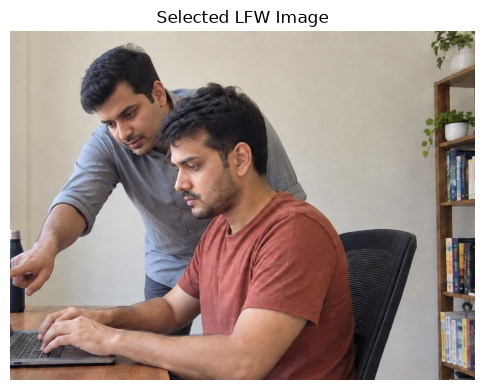

In [22]:
# Load LFW image and perform face detection

PROJECT_ROOT = Path.cwd().resolve().parent

# Search the entire project dataset directory
DATASET_PATH = PROJECT_ROOT / "dataset" / "lfw-deepfunneled"

image_paths = list(DATASET_ROOT.rglob("*.jpg"))

print("Total images found:", len(image_paths))

if not image_paths:
    raise FileNotFoundError(
        f"No JPG images found inside: {DATASET_ROOT}"
    )

# Select first image
sample_image_path = image_paths[0]

# Load image
image = cv2.imread(str(sample_image_path))

if image is None:
    raise ValueError("Unable to load image.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# MediaPipe processing
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

result = landmarker.detect(mp_image)

print("Selected image:", sample_image_path)
print("Faces detected:", len(result.face_landmarks))

# Display image
plt.figure(figsize=(6, 6))
plt.imshow(image_rgb)
plt.title("Selected LFW Image")
plt.axis("off")
plt.show()

Total LFW images found: 13233
Selected image: D:\Identity_Monitoring\dataset\lfw-deepfunneled\lfw-deepfunneled\Arnaud_Lagardere\Arnaud_Lagardere_0001.jpg
Faces detected: 1


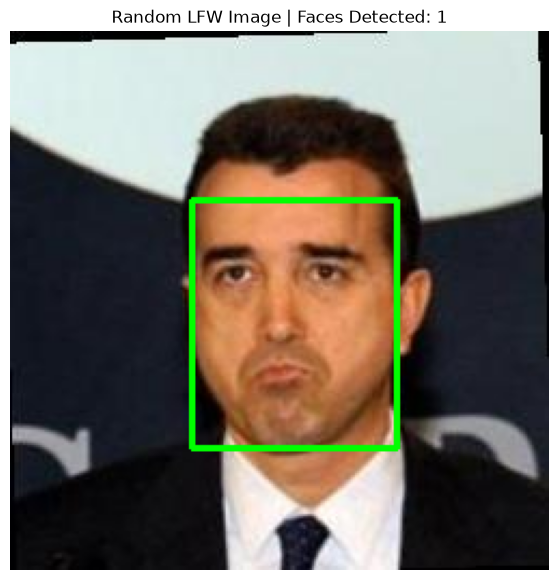

In [27]:
import random
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

# Select a random LFW image
lfw_images = list(DATASET_PATH.rglob("*.jpg"))

if not lfw_images:
    raise FileNotFoundError(
        f"No JPG images found inside {DATASET_PATH}"
    )

sample_image_path = random.choice(lfw_images)

# Load image
image = cv2.imread(str(sample_image_path))

if image is None:
    raise ValueError("Unable to load image.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Prepare MediaPipe input
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

# Detect faces
result = landmarker.detect(mp_image)
faces_detected = len(result.face_landmarks)

print("Total LFW images found:", len(lfw_images))
print("Selected image:", sample_image_path)
print("Faces detected:", faces_detected)

# Draw bounding boxes
image_display = image_rgb.copy()
height, width, _ = image_display.shape

for face_landmarks in result.face_landmarks:
    x_coords = [int(lm.x * width) for lm in face_landmarks]
    y_coords = [int(lm.y * height) for lm in face_landmarks]

    x_min = max(0, min(x_coords))
    y_min = max(0, min(y_coords))
    x_max = min(width, max(x_coords))
    y_max = min(height, max(y_coords))

    cv2.rectangle(
        image_display,
        (x_min, y_min),
        (x_max, y_max),
        (0, 255, 0),
        2
    )

# Display result
plt.figure(figsize=(8, 7))
plt.imshow(image_display)
plt.title(f"Random LFW Image | Faces Detected: {faces_detected}")
plt.axis("off")
plt.show()

Detect a face and extract its five key landmarks

Five reference points:
 [[104.03633  117.407776]
 [149.6914   116.3047  ]
 [132.05739  134.21184 ]
 [109.71873  162.23935 ]
 [147.97202  161.85606 ]]
SFace face data shape: (15,)


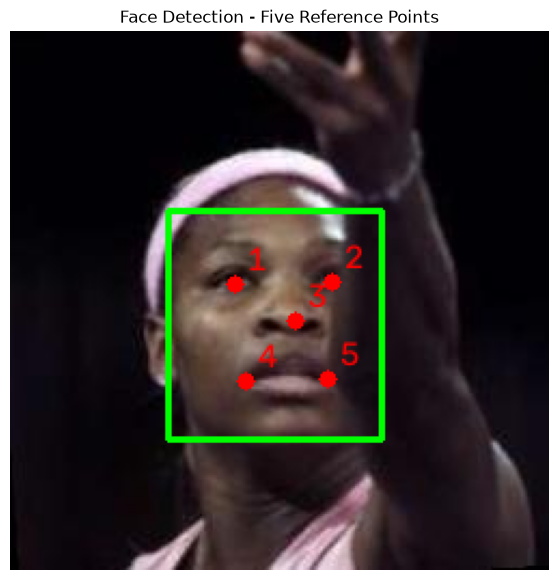


Point mapping:
1. Right eye
2. Left eye
3. Nose
4. Right mouth corner
5. Left mouth corner



In [35]:

# 1. Select a random LFW image
lfw_images = list(DATASET_PATH.rglob("*.jpg"))

if not lfw_images:
    raise FileNotFoundError("No LFW images found.")

sample_image_path = random.choice(lfw_images)

# 2. Load image
image = cv2.imread(str(sample_image_path))

if image is None:
    raise ValueError("Unable to load image.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# 3. Detect face
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

result = landmarker.detect(mp_image)

if len(result.face_landmarks) == 0:
    raise ValueError("No face detected. Run again.")

if len(result.face_landmarks) > 1:
    raise ValueError("Multiple faces detected. Select a single-face image.")

landmarks = result.face_landmarks[0]

height, width, _ = image.shape

# 4. Calculate bounding box
x_coords = [int(point.x * width) for point in landmarks]
y_coords = [int(point.y * height) for point in landmarks]

x_min = max(0, min(x_coords))
y_min = max(0, min(y_coords))
x_max = min(width - 1, max(x_coords))
y_max = min(height - 1, max(y_coords))

# 5. Extract five facial reference points

def get_point(index):
    return np.array([
        landmarks[index].x * width,
        landmarks[index].y * height
    ], dtype=np.float32)

# OpenCV SFace order:
# Right eye, Left eye, Nose, Right mouth, Left mouth

right_eye = (get_point(33) + get_point(133)) / 2
left_eye = (get_point(263) + get_point(362)) / 2

nose = get_point(1)

# Corrected mouth-corner mapping
right_mouth = get_point(61)
left_mouth = get_point(291)

five_points = np.array([
    right_eye,
    left_eye,
    nose,
    right_mouth,
    left_mouth
], dtype=np.float32)

# Prepare SFace face data
face_data = np.array([
    x_min,
    y_min,
    x_max - x_min,
    y_max - y_min,
    *five_points.flatten(),
    1.0
], dtype=np.float32)

print("Five reference points:\n", five_points)
print("SFace face data shape:", face_data.shape)

# 6. Prepare face data for SFace
face_data = np.array([
    x_min, y_min,
    x_max - x_min,
    y_max - y_min,
    *five_points.flatten()
], dtype=np.float32)

# 7. Visualize face and five reference points
image_display = image_rgb.copy()

cv2.rectangle(
    image_display,
    (x_min, y_min),
    (x_max, y_max),
    (0, 255, 0),
    2
)

# Draw numbered reference points
for i, point in enumerate(five_points):
    x, y = point.astype(int)

    cv2.circle(image_display, (x, y), 4, (255, 0, 0), -1)
    cv2.putText(
        image_display,
        str(i + 1),
        (x + 6, y - 6),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        1
    )

plt.figure(figsize=(8, 7))
plt.imshow(image_display)
plt.title("Face Detection - Five Reference Points")
plt.axis("off")
plt.show()

print("""
Point mapping:
1. Right eye
2. Left eye
3. Nose
4. Right mouth corner
5. Left mouth corner
""")


Align the face using SFace

Original image shape: (250, 250, 3)
Aligned face shape: (112, 112, 3)


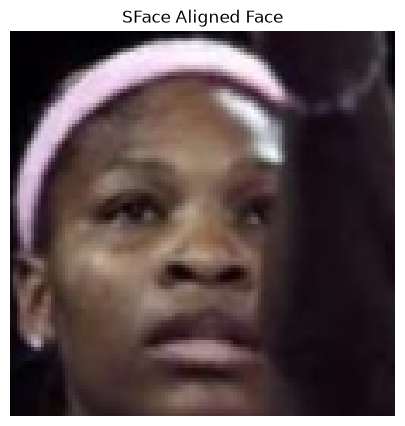

In [37]:
# Align and crop the detected face
aligned_face = recognizer.alignCrop(
    image,
    face_data.reshape(1, -1)
)

print("Original image shape:", image.shape)
print("Aligned face shape:", aligned_face.shape)

# Display aligned face
aligned_rgb = cv2.cvtColor(
    aligned_face,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(5, 5))
plt.imshow(aligned_rgb)
plt.title("SFace Aligned Face")
plt.axis("off")
plt.show()


Extract Face Embeddings

In [38]:
# Extract facial features using SFace
embedding = recognizer.feature(aligned_face)

# Convert into a one-dimensional NumPy array
embedding = embedding.flatten()

# Normalize the embedding
normalized_embedding = embedding / np.linalg.norm(embedding)

print("Embedding shape:", embedding.shape)
print("Number of dimensions:", len(embedding))
print("First 10 values:", embedding[:10])

print(
    "Embedding extraction successful:",
    embedding.shape == (128,)
)


Embedding shape: (128,)
Number of dimensions: 128
First 10 values: [-0.21410264 -1.27964    -0.50407684  0.5108617   0.39384025  0.62857246
  1.1904271  -1.0184896  -0.40835693  0.44542283]
Embedding extraction successful: True


Reusable Face Embedding System

In [39]:
def extract_face_embedding(image_path):

    # Load image
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Unable to load image: {image_path}")

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Detect face using MediaPipe
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    result = landmarker.detect(mp_image)

    if len(result.face_landmarks) == 0:
        raise ValueError("No face detected.")

    if len(result.face_landmarks) > 1:
        raise ValueError("Multiple faces detected.")

    landmarks = result.face_landmarks[0]
    height, width, _ = image.shape

    # Calculate bounding box
    x_coords = [int(point.x * width) for point in landmarks]
    y_coords = [int(point.y * height) for point in landmarks]

    x_min = max(0, min(x_coords))
    y_min = max(0, min(y_coords))
    x_max = min(width - 1, max(x_coords))
    y_max = min(height - 1, max(y_coords))

    # Extract five facial reference points
    def get_point(index):
        return np.array([
            landmarks[index].x * width,
            landmarks[index].y * height
        ], dtype=np.float32)

    right_eye = (get_point(33) + get_point(133)) / 2
    left_eye = (get_point(263) + get_point(362)) / 2
    nose = get_point(1)
    right_mouth = get_point(61)
    left_mouth = get_point(291)

    five_points = np.array([
        right_eye,
        left_eye,
        nose,
        right_mouth,
        left_mouth
    ], dtype=np.float32)

    # Prepare face data for SFace
    face_data = np.array([
        x_min,
        y_min,
        x_max - x_min,
        y_max - y_min,
        *five_points.flatten(),
        1.0
    ], dtype=np.float32)

    # Align face
    aligned_face = recognizer.alignCrop(
        image,
        face_data.reshape(1, -1)
    )

    # Extract embedding
    embedding = recognizer.feature(aligned_face).flatten()

    # Normalize embedding
    norm = np.linalg.norm(embedding)

    if norm == 0:
        raise ValueError("Invalid zero embedding.")

    normalized_embedding = embedding / norm

    return normalized_embedding


Select two images of the same person

Selected identity: Candice_Bergen
Total images of this identity: 3
Reference image: Candice_Bergen_0002.jpg
Probe image: Candice_Bergen_0001.jpg


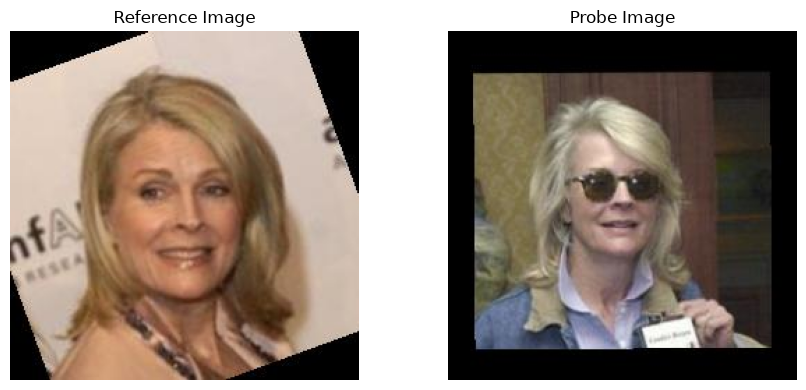

In [41]:

# 1. Find all identity folders recursively
identity_folders = [
    folder
    for folder in DATASET_PATH.rglob("*")
    if folder.is_dir()
    and len(list(folder.glob("*.jpg"))) >= 2
]

if not identity_folders:
    raise ValueError(
        f"No identity folders with multiple images found in {DATASET_PATH}"
    )

# 2. Select a random identity
selected_identity = random.choice(identity_folders)

# 3. Select two different images of that person
identity_images = list(selected_identity.glob("*.jpg"))

reference_path, probe_path = random.sample(
    identity_images, 2
)

print("Selected identity:", selected_identity.name)
print("Total images of this identity:", len(identity_images))
print("Reference image:", reference_path.name)
print("Probe image:", probe_path.name)

# 4. Display both images
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, path, title in zip(
    axes,
    [reference_path, probe_path],
    ["Reference Image", "Probe Image"]
):
    img = cv2.cvtColor(
        cv2.imread(str(path)),
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


Identity verification

In [42]:
# Extract embeddings from both images
reference_embedding = extract_face_embedding(reference_path)
probe_embedding = extract_face_embedding(probe_path)

# Calculate cosine similarity
similarity = float(
    np.dot(reference_embedding, probe_embedding)
)

# Initial SFace cosine similarity threshold
THRESHOLD = 0.363

# Determine identity
if similarity >= THRESHOLD:
    verification_result = "MATCH"
else:
    verification_result = "MISMATCH"

print("Reference embedding shape:", reference_embedding.shape)
print("Probe embedding shape:", probe_embedding.shape)
print("Cosine similarity:", round(similarity, 4))
print("Threshold:", THRESHOLD)
print("Verification result:", verification_result)


Reference embedding shape: (128,)
Probe embedding shape: (128,)
Cosine similarity: 0.5783
Threshold: 0.363
Verification result: MATCH


Select a different identity

Reference identity: Candice_Bergen
Probe identity: Dave_Campo
Probe image: Dave_Campo_0001.jpg


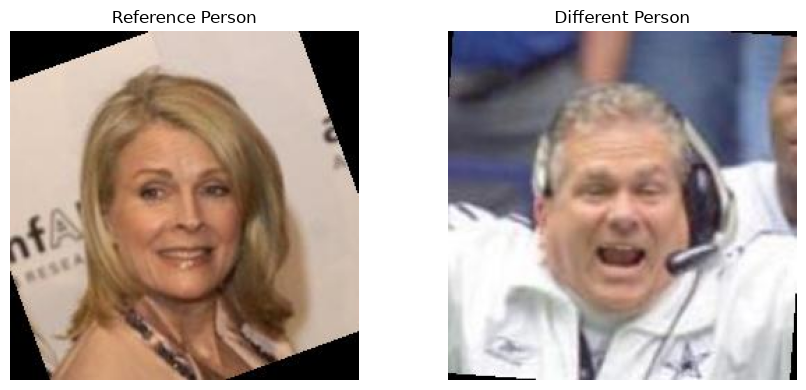

In [46]:
# Keep the existing reference image and embedding
# Select a different identity from LFW

different_identity_folders = [
    folder
    for folder in DATASET_PATH.rglob("*")
    if folder.is_dir()
    and folder.name != selected_identity.name
    and len(list(folder.glob("*.jpg"))) >= 1
]

if not different_identity_folders:
    raise ValueError("No other identities found.")

# Select another person
impostor_identity = random.choice(different_identity_folders)

# Select one photograph
impostor_images = list(impostor_identity.glob("*.jpg"))
impostor_path = random.choice(impostor_images)

print("Reference identity:", selected_identity.name)
print("Probe identity:", impostor_identity.name)
print("Probe image:", impostor_path.name)

# Display both photographs
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, path, title in zip(
    axes,
    [reference_path, impostor_path],
    ["Reference Person", "Different Person"]
):
    img = cv2.cvtColor(
        cv2.imread(str(path)),
        cv2.COLOR_BGR2RGB
    )
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [47]:

# Extract embedding of the different person
impostor_embedding = extract_face_embedding(impostor_path)

# Compare with the original reference embedding
impostor_similarity = float(
    np.dot(reference_embedding, impostor_embedding)
)

# Apply the same initial threshold
THRESHOLD = 0.363

if impostor_similarity >= THRESHOLD:
    impostor_result = "MATCH"
else:
    impostor_result = "MISMATCH"

print("Reference embedding shape:", reference_embedding.shape)
print("Impostor embedding shape:", impostor_embedding.shape)
print("Cosine similarity:", round(impostor_similarity, 4))
print("Threshold:", THRESHOLD)
print("Verification result:", impostor_result)


Reference embedding shape: (128,)
Impostor embedding shape: (128,)
Cosine similarity: 0.1672
Threshold: 0.363
Verification result: MISMATCH
